# Statistics 5: Sampling and the central limit theorem

*Learning path: probability and statistics, part 5 of 8.* [Index](README.md) · Previous: [Continuous distributions](04-continuous-distributions.ipynb) · Next: [Estimation and confidence](06-estimation-and-confidence.ipynb)

A poll of 1000 voters finds 52% for a candidate. Should the candidate celebrate? The 1000 people are a **sample** from
millions, and a different 1000 would give a different percentage. How different? Two theorems answer that. The **law of
large numbers** says that averages settle down as samples grow. The **central limit theorem** says how they scatter on
the way: like a bell curve, whatever the shape of the data. It is the reason the normal distribution of
[lesson 4](04-continuous-distributions.ipynb) appears everywhere, and the foundation of the confidence intervals and
tests in lessons 6 and 7.

**Who this is for.** You have done lessons 1 to 4. No new mathematics is needed; the ideas come from simulation.

**What you will be able to do afterwards:**

1. watch the law of large numbers at work in a running average;
2. describe the sampling distribution of a mean, with its centre and its standard error $\sigma/\sqrt n$;
3. state the central limit theorem and see it turn dice, uniform and exponential data into bell curves;
4. compute the margin of error of a poll.

Plan about an hour.

## 1. The law of large numbers

Roll a die 10,000 times and keep a running average: after $n$ rolls, the sum of the first $n$ rolls divided by $n$.
`cumsum` gives the running sums, `k = 1:10000` the numbers $1, 2, \ldots, 10000$, and `./` divides one list by another
entry by entry:

[2.9, 3.38, 3.529, 3.498]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

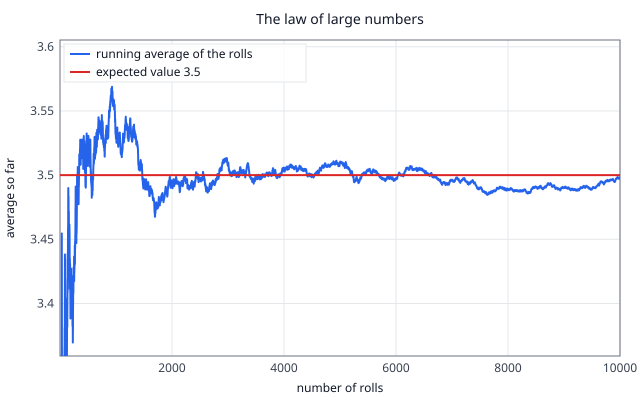

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
seed(5);
x = randint(1, 6, 1, 10000);
k = 1:10000;
r = cumsum(x)./k;
eval([r(10), r(100), r(1000), r(10000)])
p = plot(k, r);
p = show(p, plot(7/2, n, 1, 10000));
p = legend(p, "running average of the rolls", "expected value 3.5");
labels(title(p, "The law of large numbers"), "number of rolls", "average so far")

After 10 rolls the average is 2.9, after 10,000 it is 3.498: it closes in on the expected value $3.5$ of
[lesson 3](03-discrete-distributions.ipynb). This is the **law of large numbers**: the average of $n$ independent
draws tends to the expected value as $n$ grows. It does not say that the dice "make up" for a run of low numbers; the
early rolls are simply outweighed by the many that follow.

**Try this.** Run the cell with `seed(6)` instead. Is the path the same? Does it end near 3.5?

## 2. The sampling distribution of a mean

Now take many samples of the same size and look at how their averages vary. A $10 \times 2000$ matrix of rolls has one
sample of 10 rolls in each column; multiplying by a row of ten ones adds each column, and dividing by 10 gives 2000
sample means. The means are multiples of 0.1, so the histogram gets bins of width 0.2 centred on them:

[3.4881, 0.5446620221377471]

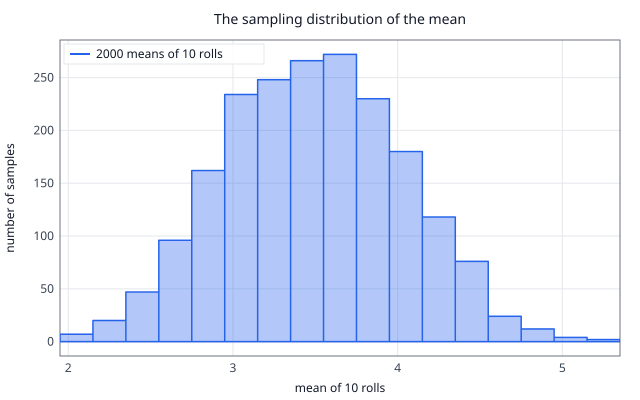

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
A = randint(1, 6, 10, 2000);
m = ones(1, 10)*A/10;
[eval(mean(m)), eval(std(m))]
p = hist(m, 1.95:0.2:5.35);
labels(title(legend(p, "2000 means of 10 rolls"), "The sampling distribution of the mean"), "mean of 10 rolls", "number of samples")

The 2000 averages centre on 3.5, and they are much less spread out than single rolls. A single roll has variance
$\sigma^2 = 35/12$ (the average of $(k - 3.5)^2$ over the six faces). Averaging $n$ independent values divides the
variance by $n$, so the standard deviation of a mean, the **standard error**, is

$$\operatorname{SE} = \frac{\sigma}{\sqrt n}.$$

In [3]:
sigma = sqrt(35/12)
eval(sigma/sqrt(10))

sqrt(35/3)/2

> `sqrt`: Square root; sqrt(-1) is the imaginary unit i.

0.5400617248673216

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.540, and the simulation gave 0.545. To halve the standard error you need four times as many observations: the
$\sqrt n$ is why precision is expensive.

**Try this.** Repeat with samples of 40 rolls (`randint(1, 6, 40, 2000)` and `ones(1, 40)`). What standard error do you
expect, and what do you get?

## 3. The central limit theorem

The histogram of means already looked like a bell. The **central limit theorem** says that this always happens: for
independent draws from any distribution with mean $\mu$ and standard deviation $\sigma$, the sample mean is
approximately normal with mean $\mu$ and standard deviation $\sigma/\sqrt n$, and the approximation improves as $n$
grows.

A classic check: a uniform number on $[0, 1]$ has mean $1/2$ and variance $1/12$. The sum of 12 of them, minus 6, has
mean 0 and variance $12 \cdot \tfrac{1}{12} = 1$. The central limit theorem says it is nearly standard normal:

[0.013059518850448457, 0.99577170911006]

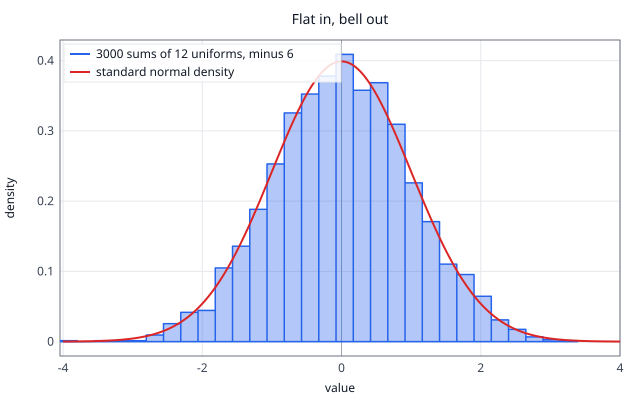

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
U = rand(12, 3000);
z = ones(1, 12)*U - 6;
[eval(mean(z)), eval(std(z))]
p = hist(z, 30, "density");
p = show(p, plot(normpdf(x), x, -4, 4));
p = legend(p, "3000 sums of 12 uniforms, minus 6", "standard normal density");
labels(title(p, "Flat in, bell out"), "value", "density")

Twelve flat distributions add up to a bell. (This was once a standard way for computers to make normal random
numbers.) The theorem works even for very skewed data. Lifetimes from the exponential distribution of lesson 4, with
mean 1 and standard deviation 1, are strongly skewed; their averages over 30 bulbs are not:

[1.0070057837620103, 0.18628847738846593, 0.18257418583505536]

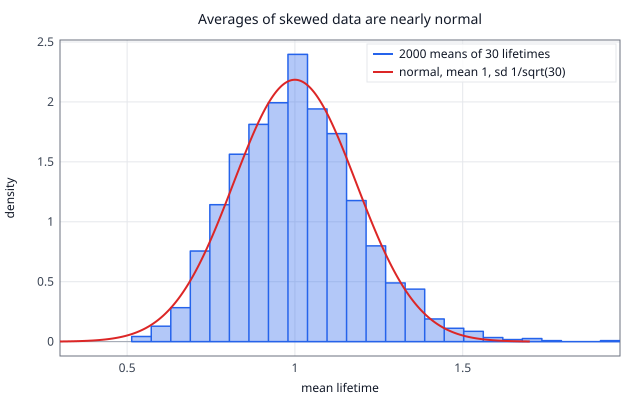

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
T = -log(rand(30, 2000));
mt = ones(1, 30)*T/30;
[eval(mean(mt)), eval(std(mt)), eval(1/sqrt(30))]
p = hist(mt, 25, "density");
p = show(p, plot(normpdf(x, 1, 1/sqrt(30)), x, 0.3, 1.7));
p = legend(p, "2000 means of 30 lifetimes", "normal, mean 1, sd 1/sqrt(30)");
labels(title(p, "Averages of skewed data are nearly normal"), "mean lifetime", "density")

The averages have standard deviation 0.186 against $1/\sqrt{30} = 0.183$, and a mostly symmetric histogram; a slight
leftover skew to the right is visible, which would shrink with larger samples.

**Try this.** Repeat the exponential experiment with samples of size 3 (`rand(3, 2000)`, `ones(1, 3)`, divide by 3).
Does the histogram still look normal?

## 4. Proportions and the margin of error

A poll asks yes-or-no questions, and the fraction of yeses is an average of zeros and ones. If the true support is
$p$, one answer has mean $p$ and standard deviation $\sqrt{p(1 - p)}$, so a poll of $n$ people has standard error
$\sqrt{p(1 - p)/n}$. Simulate 2000 polls of 1000 voters when the true support is 52%:

[0.015745227398895244, 0.0157987341265052]

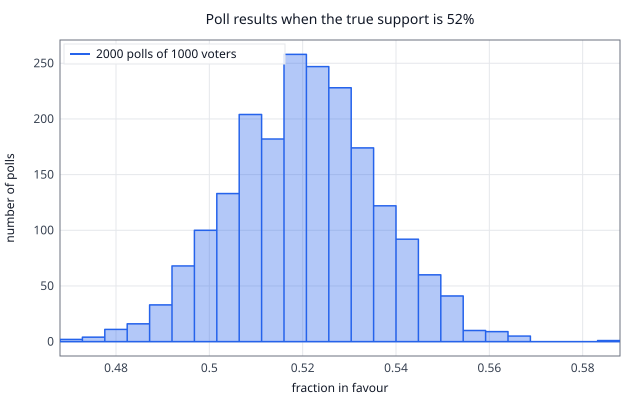

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
v = randbin(1000, 0.52, 2000)/1000;
[eval(std(v)), eval(sqrt(0.52*0.48/1000))]
p = hist(v, 25);
labels(title(legend(p, "2000 polls of 1000 voters"), "Poll results when the true support is 52%"), "fraction in favour", "number of polls")

The standard error is about 0.016, so by the 95% rule of lesson 4 most polls land within $1.96 \times 0.016 \approx
0.03$ of the truth. That is the **margin of error** of "plus or minus 3 points" quoted with polls of 1000 people.
Even with a true majority, about one poll in ten shows the candidate losing:

In [7]:
sum(v < 0.5)/2000
eval(normcdf(0.5, 0.52, sqrt(0.52*0.48/1000)))

12/125

0.10277010911130924

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The simulated 9.6% and the normal approximation's 10.3% agree. So 52% in one poll of 1000 is encouraging, not
decisive.

**Try this.** How large must a poll be for a margin of error of 1 point? Solve $1.96\sqrt{0.25/n} = 0.01$ (the worst
case $p = 1/2$).

## Summary

* Law of large numbers: the average of $n$ independent draws tends to the expected value.
* The sample mean has mean $\mu$ and standard error $\sigma/\sqrt n$; four times the data halves the error.
* Central limit theorem: sample means are approximately normal, whatever the shape of the data, and more so as $n$
  grows.
* A proportion from $n$ answers has standard error $\sqrt{p(1 - p)/n}$; the 95% margin of error is about 1.96 standard
  errors, about 3 points for $n = 1000$.

Next: [estimation and confidence](06-estimation-and-confidence.ipynb), where we turn this around and estimate an
unknown $\mu$ from one sample.

## Exercises

1. **Coin flips.** Make a running average of 5000 coin flips (`randint(0, 1, 1, 5000)`) and plot it with the line
   $1/2$.
2. **Standard error by hand.** Heights have standard deviation 8 cm. What is the standard error of the mean height of
   a sample of 64 people?
3. **The square-root law.** A sample of 100 gives a standard error of 2. What sample size gives a standard error of
   0.5?
4. **Sums of dice.** The sum of 100 dice has mean 350. What is its standard deviation? Estimate $P(\text{sum} > 370)$
   with `normcdf`.
5. **When the theorem fails.** The Cauchy distribution of lesson 4, exercise 5, has no mean. Its values can be made
   with `tan(pi*(rand(1, 1000) - 1/2))`. Make a running average. Does it settle down?

## Hints and answers

* **Section 1, Try this.** A different path, which also ends near 3.5.
* **Section 2, Try this.** $\sqrt{35/12}/\sqrt{40} \approx 0.27$, half of the value for 10 rolls.
* **Section 3, Try this.** No: with only 3 values the means are still visibly skewed to the right.
* **Section 4, Try this.** $n = (1.96 \cdot 0.5/0.01)^2 \approx 9604$ people.
* **Exercise 2.** $8/\sqrt{64} = 1$ cm.
* **Exercise 3.** The error must shrink 4 times, so 16 times the data: 1600.
* **Exercise 4.** $\sqrt{100 \cdot 35/12} \approx 17.1$; `1 - normcdf(370, 350, sqrt(100*35/12))` $\approx 0.12$.
* **Exercise 5.** No: rare huge values keep throwing the average off, however long you wait.

## Sources

1. J. Bernoulli, *Ars Conjectandi*, Basel (1713), part 4 (the first law of large numbers).
2. P. S. Laplace, *Théorie analytique des probabilités*, Paris (1812) (the central limit theorem).
3. D. Freedman, R. Pisani and R. Purves, *Statistics*, 4th ed., Norton (2007), chapters 16 to 21.
4. W. Feller, *An Introduction to Probability Theory and Its Applications*, vol. 1, 3rd ed., Wiley (1968), chapter 10.